In [7]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import torchvision.transforms as transforms

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

num_epochs = 15
batch_size = 32
learning_rate = 0.01

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

train_set = torchvision.datasets.CIFAR10(root='./data', train=True, download=True, transform=transform)
train_loader = torch.utils.data.DataLoader(train_set, batch_size=batch_size, shuffle=True)

test_set = torchvision.datasets.CIFAR10(root='./data', train=False, download=True, transform=transform)
test_loader = torch.utils.data.DataLoader(test_set, batch_size=batch_size, shuffle=False)


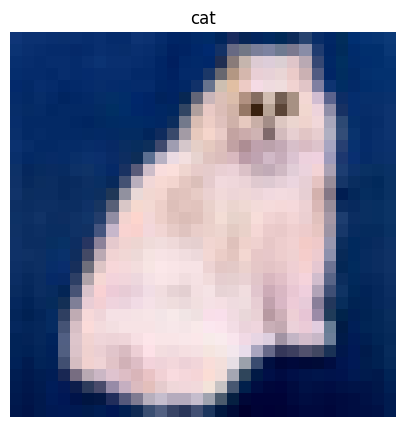

In [8]:
import matplotlib.pyplot as plt
import numpy as np
classes = ('plane', 'car', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck')

imagens, labels = next(iter(train_loader))

plt.figure(figsize=(10, 5))
plt.imshow(np.transpose(imagens.numpy()[0], (1, 2, 0)))
plt.title(classes[labels[0]])
plt.axis('off')
plt.show()

In [9]:
class ConvNet(nn.Module):
  def __init__(self):
    super().__init__()
    self.conv1 = nn.Conv2d(3, 6, 5)
    self.pool = nn.MaxPool2d(2, 2)
    self.conv2 = nn.Conv2d(6, 16, 5)
    self.fc1 = nn.Linear(16*5*5, 120)
    self.fc2 = nn.Linear(120, 84)
    self.fc3 = nn.Linear(84, 10)

  def forward(self, x):
    x = self.pool(F.relu(self.conv1(x)))
    x = self.pool(F.relu(self.conv2(x)))
    x = torch.flatten(x, 1)
    x = F.relu(self.fc1(x))
    x = F.relu(self.fc2(x))
    return self.fc3(x)

model = ConvNet().to(device)

In [10]:
criterion = nn.CrossEntropyLoss()
# Trocando o SGD com momentum pelo Adam (otimizador adaptativo)
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

for epoch in range(num_epochs):
  model.train()
  running_loss = 0.0
  for images, labels, in train_loader:
    images, labels = images.to(device), labels.to(device)

    outputs = model(images)
    loss = criterion(outputs, labels)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    running_loss += loss.item()
  print(f'Epoca {epoch+1}/{num_epochs}, Perda: {running_loss/len(train_loader):.4f}')

Epoca 1/15, Perda: 1.8774
Epoca 2/15, Perda: 1.7364
Epoca 3/15, Perda: 1.6873
Epoca 4/15, Perda: 1.6365
Epoca 5/15, Perda: 1.6191
Epoca 6/15, Perda: 1.6116
Epoca 7/15, Perda: 1.5972
Epoca 8/15, Perda: 1.5888
Epoca 9/15, Perda: 1.5904
Epoca 10/15, Perda: 1.5860
Epoca 11/15, Perda: 1.5689
Epoca 12/15, Perda: 1.5507
Epoca 13/15, Perda: 1.5822
Epoca 14/15, Perda: 1.5610
Epoca 15/15, Perda: 1.5526


In [11]:
classes = ('plane', 'car', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck')

model.eval()
correct, total = 0, 0
class_correct, class_total = [0] * 10, [0] * 10

with torch.no_grad():                            # não precisa de gradientes no teste
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        _, predicted = torch.max(outputs, 1)     # classe com o maior score
        total += labels.size(0)
        correct += (predicted == labels).sum().item()
        for l, p in zip(labels.tolist(), predicted.tolist()):
            class_total[l] += 1
            class_correct[l] += int(l == p)

print(f'Acurácia geral: {100 * correct / total:.1f}%')
for i in range(10):
    print(f'{classes[i]:>9}: {100 * class_correct[i] / class_total[i]:.1f}%')

Acurácia geral: 42.0%
    plane: 29.4%
      car: 26.9%
     bird: 27.6%
      cat: 21.7%
     deer: 37.5%
      dog: 60.2%
     frog: 52.0%
    horse: 49.5%
     ship: 58.0%
    truck: 57.0%
